In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Task 1 — Data Import & Setup 

Import CSV using Pandas 

Check/convert data types 

Convert date columns to datetime 

Use NumPy arrays for basic array operations 

## Task 2 — Data Cleaning 

### Cleaning Missing Data 

Detect missing values (isnull(), isna()) 

Handle using: dropna(), fillna(), median/mode, forward/backward-fill 

### Duplicate Handling 

Identify & remove duplicates 

### Data Formatting 

Fix incorrect data types 

Standardize categories (e.g., gender labels) 

Correct unrealistic values in likes, comments, shares 

### Feature Cleaning 

Extract hashtag count 

Clean sentiment labels 
 

In [2]:
df=pd.read_csv(r"C:\Users\ajith\Downloads\social_media_engagement_5000.csv")

In [3]:
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518


### Cleaning Missing Data

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [5]:
df["posted_at"]=pd.to_datetime(df["posted_at"],dayfirst=True)
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [6]:
comments_array=df["comments"].to_numpy()
comments_array

array([ 354., 2606.,  344., ...,   nan, 1289.,  503.], shape=(5000,))

In [7]:
comments_mean=np.nanmean(comments_array)
comments_mean

np.float64(1502.1956701030929)

In [8]:
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [9]:
df['age']=df['age'].fillna(df['age'].median())

In [10]:
df['gender']=df['gender'].fillna('unknown')

In [11]:
df['likes']=df['likes'].fillna(df['likes'].mean())

In [12]:
df['comments']=df['comments'].fillna(df['comments'].mean())

In [13]:
df['shares']=df['shares'].fillna(df['shares'].mean())

In [14]:
df['sentiment']=df['sentiment'].fillna(df['sentiment'].mode()[0])

In [15]:
df["sentiment"] = df["sentiment"].ffill()

### Duplicate Handling

In [16]:
df.duplicated().sum()      #no duplicates 

np.int64(0)

### Data Formatting

In [17]:
df['age']=df['age'].astype(int)
df['likes']=df['likes'].astype(int)
df['comments']=df['comments'].astype(int)
df['shares']=df['shares'].astype(int)
df.info() 
df

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32,Female,UK,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34,Other,UK,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63,Female,USA,273595,text,travel,13487,1502,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [18]:
for i in df.select_dtypes(include=['bool','str']).columns:
    df[i] = df[i].astype(str).str.strip().str.title()
df    

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#Foodie #Travel #Love,0.190862
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#Fitness,0.201493
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#Foodie,0.137345
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#Music #Foodie #Fun,0.106195
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#Travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,Positive,#Travel #Fun,0.466761
4996,22100,38,Other,Uae,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,Negative,#Foodie #Reels,0.621155
4997,67021,63,Female,Usa,273595,Text,Travel,13487,1502,167,7466,23680,2023-04-06,483550,False,Desktop,Positive,#Lifestyle #Tech,0.679688
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,Positive,#Reels #Love #Fitness,0.223518


In [19]:
df[["likes", "comments", "shares"]].describe()           #there are no obvious unrealistic values in likes, comments, and shares.

,likes,comments,shares
count,5000.000000,5000.000000,5000.000000
mean,10107.042400,1502.189800,1002.610600
std,5702.293011,856.392854,570.852972
min,10.000000,0.000000,0.000000
25%,5235.000000,792.000000,511.000000
50%,10107.000000,1502.000000,1002.000000
75%,14959.000000,2235.250000,1483.000000
max,19998.000000,2999.000000,1999.000000


### Feature Cleaning

In [20]:
df['hashtags'].str.count('#').sum()

np.int64(9993)

In [21]:
df["sentiment"] = df["sentiment"].str.strip().str.lower()
df["sentiment"]

0       negative
1       negative
2       positive
3       negative
4       negative
          ...   
4995    positive
4996    negative
4997    positive
4998    positive
4999     neutral
Name: sentiment, Length: 5000, dtype: str

In [22]:
df.columns=df.columns.str.strip()

## Task 3 — Data Exploration using Pandas 

Perform the following: 

View dataset structure using head(), tail(), shape, and columns. 

Check data types and info with info() and dtypes. 

Generate summary statistics using describe(). 

Analyze categorical distributions using value_counts(), unique(), and nunique(). 

Create a correlation matrix for numeric fields. 

Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country). 

In [23]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,negative,#Foodie #Travel #Love,0.190862
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,negative,#Fitness,0.201493
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,positive,#Foodie,0.137345
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,negative,#Music #Foodie #Fun,0.106195
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,negative,#Travel,2.777372


In [24]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,positive,#Travel #Fun,0.466761
4996,22100,38,Other,Uae,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,negative,#Foodie #Reels,0.621155
4997,67021,63,Female,Usa,273595,Text,Travel,13487,1502,167,7466,23680,2023-04-06,483550,False,Desktop,positive,#Lifestyle #Tech,0.679688
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,positive,#Reels #Love #Fitness,0.223518
4999,73400,54,Other,Japan,712252,Text,Travel,14830,503,1798,3743,14234,2023-03-04,585760,False,Desktop,neutral,#Foodie #Lifestyle #Fashion,1.203527


In [25]:
df.shape

(5000, 19)

In [26]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   s

In [28]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10107.042400,1502.189800,1002.610600,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.000000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10107.000000,1502.000000,1002.000000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.000000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348
std,26090.370121,14.687151,260646.957267,5702.293011,856.392854,570.852972,2308.096459,28844.939104,NaN,230927.884535,5.318029


In [29]:
df['post_category'].value_counts()

post_category
Fitness      675
Tech         665
Music        635
Education    631
Lifestyle    607
Travel       600
Fashion      594
Food         593
Name: count, dtype: int64

In [30]:
df['post_category'].unique()

<ArrowStringArray>
[  'Fitness',      'Food',      'Tech',    'Travel',   'Fashion', 'Lifestyle',
 'Education',     'Music']
Length: 8, dtype: str

In [31]:
df['post_category'].nunique()

8

In [32]:
df.corr(numeric_only=True)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
user_id,1.000000,-0.006688,0.020051,0.025812,-0.033375,0.013786,-0.016847,0.015326,0.010124,-0.004282
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013864,0.005542,0.013322,-0.024894,0.008039
post_id,0.020051,-0.013153,1.000000,0.014527,-0.010542,0.001874,0.018374,-0.007709,-0.002844,0.010139
likes,0.025812,-0.036322,0.014527,1.000000,-0.018424,0.004648,0.008711,0.007953,-0.022981,0.093520
comments,-0.033375,-0.007284,-0.010542,-0.018424,1.000000,0.006130,-0.016347,-0.009392,-0.011742,0.000046
shares,0.013786,0.013864,0.001874,0.004648,0.006130,1.000000,0.014672,-0.005086,-0.010738,0.021729
watch_time_sec,-0.016847,0.005542,0.018374,0.008711,-0.016347,0.014672,1.000000,-0.004335,0.002761,-0.001148
impression_count,0.015326,0.013322,-0.007709,0.007953,-0.009392,-0.005086,-0.004335,1.000000,-0.015513,-0.232226
follower_count,0.010124,-0.024894,-0.002844,-0.022981,-0.011742,-0.010738,0.002761,-0.015513,1.000000,0.002292
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000046,0.021729,-0.001148,-0.232226,0.002292,1.000000


In [33]:
df.groupby("post_type")[["likes","shares"]].mean()

,likes,shares
post_type,,
Image,10104.903769,1019.000802
Reel,10037.855027,981.738114
Text,10100.195181,1013.684337
Video,10188.641633,996.532245


## Task 4 — Data Wrangling  

Use merge, concat, or join if combining DataFrames. 

Create new fields such as engagement_score, log-transformed metrics (optional), and hashtag_count. 

Perform groupby summaries by post_type, country, and sentiment. 

In [34]:
df["engagement_score"] = df["likes"] + df["comments"] + df["shares"]
df["engagement_score"] 

0        8522
1       16163
2        6161
3        7482
4       16717
        ...  
4995    20060
4996    21241
4997    15156
4998    19896
4999    17131
Name: engagement_score, Length: 5000, dtype: int64

In [35]:
df['hashtag_counts']=df['hashtags'].str.count('#')
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,engagement_score,hashtag_counts
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,...,44650,2022-12-17,81734,False,Mobile,negative,#Foodie #Travel #Love,0.190862,8522,3
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,...,80216,2023-06-02,5963,False,Mobile,negative,#Fitness,0.201493,16163,1
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,...,44858,2023-05-07,501783,False,Tablet,positive,#Foodie,0.137345,6161,1
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,...,70455,2023-02-12,480212,False,Mobile,negative,#Music #Foodie #Fun,0.106195,7482,3
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,...,6019,2023-05-23,383936,False,Mobile,negative,#Travel,2.777372,16717,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,...,42977,2022-06-25,646147,False,Mobile,positive,#Travel #Fun,0.466761,20060,2
4996,22100,38,Other,Uae,677076,Reel,Education,16924,2734,1583,...,34196,2022-11-18,584603,False,Desktop,negative,#Foodie #Reels,0.621155,21241,2
4997,67021,63,Female,Usa,273595,Text,Travel,13487,1502,167,...,23680,2023-04-06,483550,False,Desktop,positive,#Lifestyle #Tech,0.679688,15156,2
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,...,89013,2022-05-16,183295,False,Tablet,positive,#Reels #Love #Fitness,0.223518,19896,3


In [36]:
summary_stats = df.groupby(['post_type','country','sentiment']).agg(
    avg_likes=('likes', 'mean'),
    total_shares=('shares', 'sum'),
    post_count=('likes', 'count')
).reset_index()
summary_stats

,post_type,country,sentiment,avg_likes,total_shares,post_count
0,Image,Australia,negative,8006.210526,18897,19
1,Image,Australia,neutral,9683.714286,48578,42
2,Image,Australia,positive,10234.727273,70969,66
3,Image,Brazil,negative,7559.350000,20201,20
4,Image,Brazil,neutral,8409.695652,51789,46
...,...,...,...,...,...,...
115,Video,Uk,neutral,10291.111111,38823,36
116,Video,Uk,positive,9011.400000,61750,65
117,Video,Usa,negative,10290.450000,20993,20
118,Video,Usa,neutral,9592.750000,36794,40


## Task 5 — Statistical Analysis  

Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate, followers: 

Mean, median, mode 

Standard deviation, variance 

Percentiles 

(Optional) Skewness and kurtosis 

In [37]:
columns_list= [
    "likes",
    "comments",
    "shares",
    "watch_time_sec",
    "engagement_rate",
    "follower_count",
]

In [38]:
status=df[columns_list].agg(["mean","median"])
status

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
mean,10107.0424,1502.1898,1002.6106,4014.5032,0.964356,393698.2248
median,10107.0000,1502.0000,1002.0000,4034.5000,0.253896,388982.0000


In [39]:
modes = df[columns_list].mode().iloc[0]
print(modes)

likes               10107.000000
comments             1502.000000
shares               1002.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64


In [40]:
df[columns_list].describe()   

#  another mwthod---- df[columns_list].quantile(0.25,0.50,0.75)

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,10107.042400,1502.189800,1002.610600,4014.503200,0.964356,393698.224800
std,5702.293011,856.392854,570.852972,2308.096459,5.318029,230927.884535
min,10.000000,0.000000,0.000000,0.000000,0.006363,87.000000
25%,5235.000000,792.000000,511.000000,2017.750000,0.145781,194480.000000
50%,10107.000000,1502.000000,1002.000000,4034.500000,0.253896,388982.000000
75%,14959.000000,2235.250000,1483.000000,6020.250000,0.504794,589744.250000
max,19998.000000,2999.000000,1999.000000,7998.000000,191.504348,799533.000000


In [41]:
df[columns_list].var()    #Variance

likes              3.251615e+07
comments           7.334087e+05
shares             3.258731e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64

In [42]:
df[columns_list].skew()       # Skewness and kurtosis values showing High variance in engagement_rate is likely caused by the presence of high outliers.

likes              -0.006917
comments            0.003276
shares             -0.013077
watch_time_sec     -0.018196
engagement_rate    18.781271
follower_count      0.041118
dtype: float64

In [43]:
df[columns_list].kurt()

likes               -1.149992
comments            -1.144373
shares              -1.146857
watch_time_sec      -1.195652
engagement_rate    482.991739
follower_count      -1.189474
dtype: float64

## Task 6 — Data Visualization (Min. 8 Plots Required) 

### Matplotlib 

Scatter: likes vs impressions 

Line: daily engagement trend 

Bar: posts by category 

Pie: gender distribution 

Histogram: age 

Box: engagement rate 

 

### Seaborn 

Count plot: post type 

Bar plot: avg likes by category 

Violin: followers vs sentiment 

Pair plot: numeric features 

Heatmap: correlation matrix 

Swarm plot: engagement vs device 

Plotly (Interactive) 

Interactive line chart/bar chart/bubble/scatter chart  

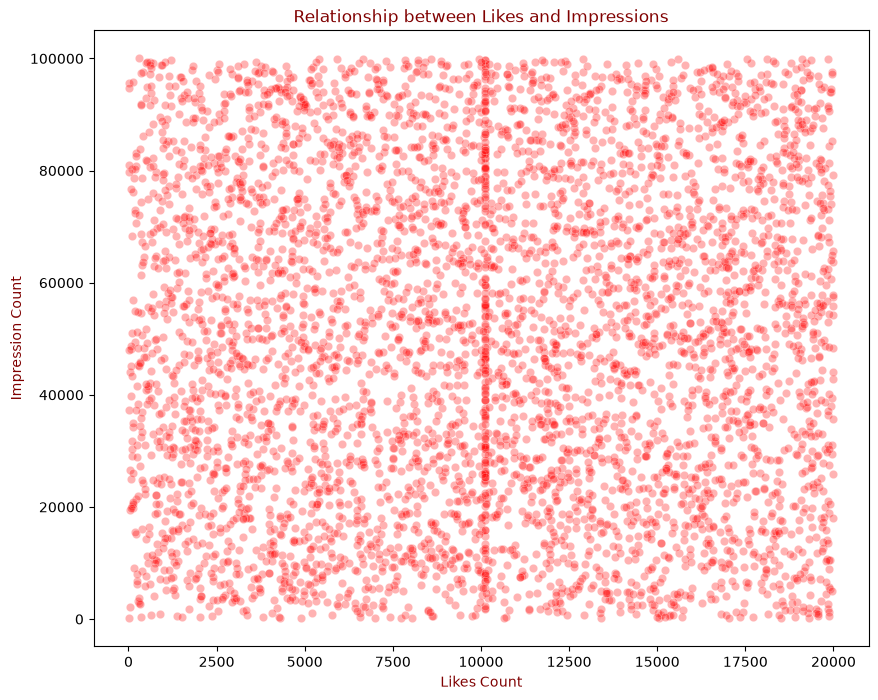

In [80]:
plt.figure(figsize=(10,8))
sns.scatterplot(data=df, x="likes", y="impression_count", color="red",alpha=0.3)
plt.title("Relationship between Likes and Impressions", color="maroon")
plt.xlabel("Likes Count", color="maroon")
plt.ylabel("Impression Count", color="maroon")
plt.show()

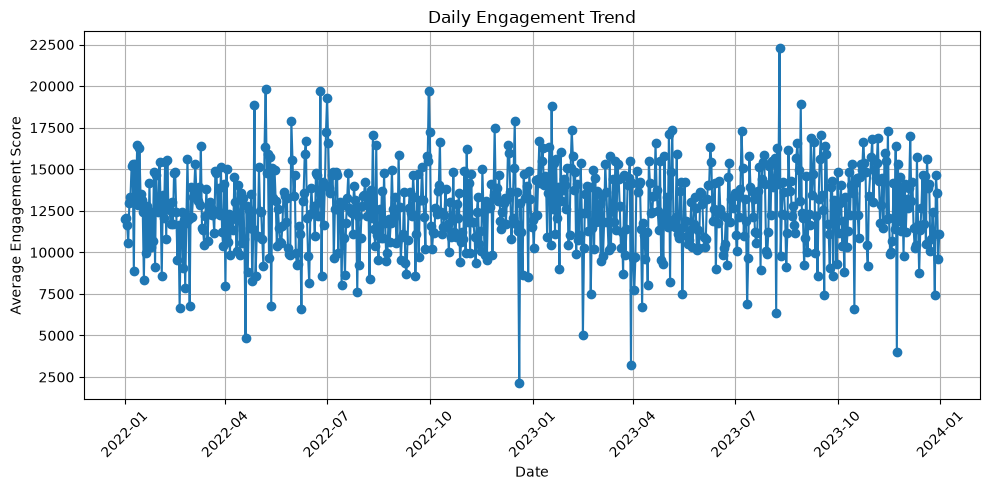

In [44]:
df["posted_at"] = pd.to_datetime(df["posted_at"])

daily = df.groupby(df["posted_at"].dt.date)["engagement_score"].mean()

plt.figure(figsize=(10, 5))
plt.plot(daily.index, daily.values, marker="o")

plt.xlabel("Date")
plt.ylabel("Average Engagement Score")
plt.title("Daily Engagement Trend")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

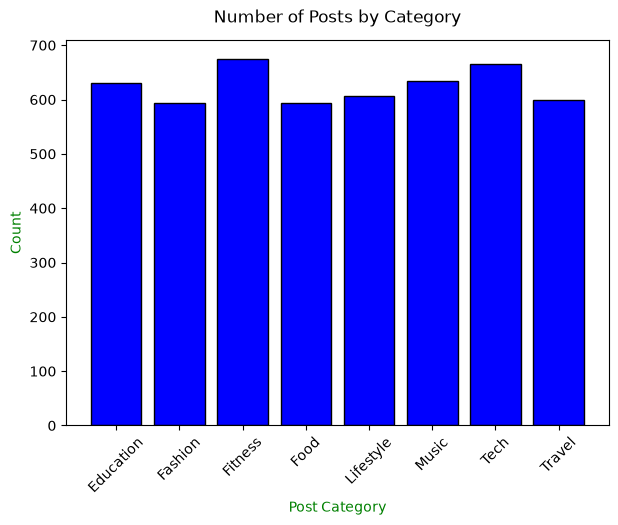

In [45]:
post_count = df.groupby('post_category')['likes'].count()

plt.figure(figsize=(7,5))
plt.bar(post_count.index, post_count.values, color='blue', edgecolor='black')
plt.title('Number of Posts by Category', fontsize=12, pad=13)
plt.xlabel('Post Category', fontsize=10,color='green')
plt.ylabel('Count', fontsize=10,color='green')
plt.xticks(rotation=45)
plt.show()

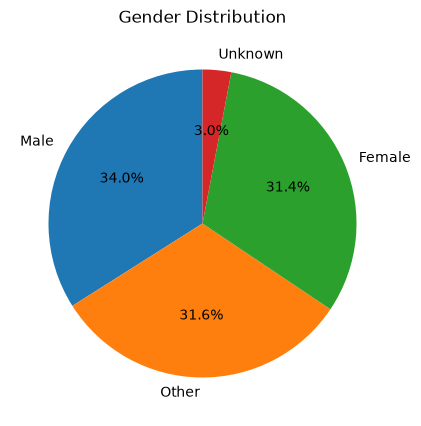

In [46]:
gender_counts = df["gender"].value_counts()
plt.figure(figsize=(5,5))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90)
plt.title("Gender Distribution")
plt.show()

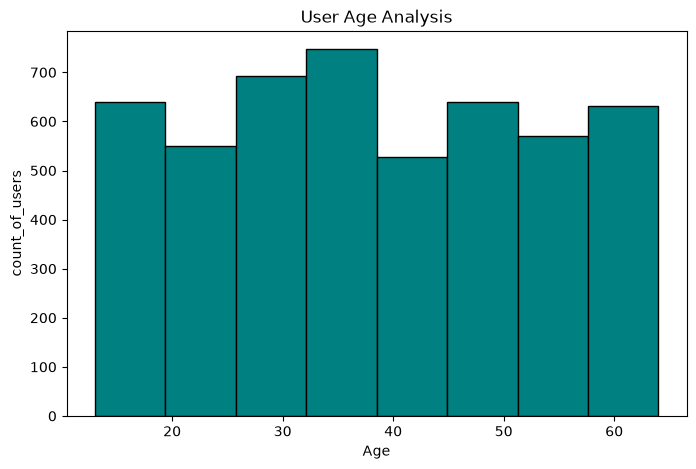

In [71]:
plt.figure(figsize=(8,5))
plt.hist(x=df['age'],bins=8,color='teal',edgecolor='black')
plt.title('User Age Analysis')
plt.xlabel('Age')
plt.ylabel('count_of_users')
plt.show()

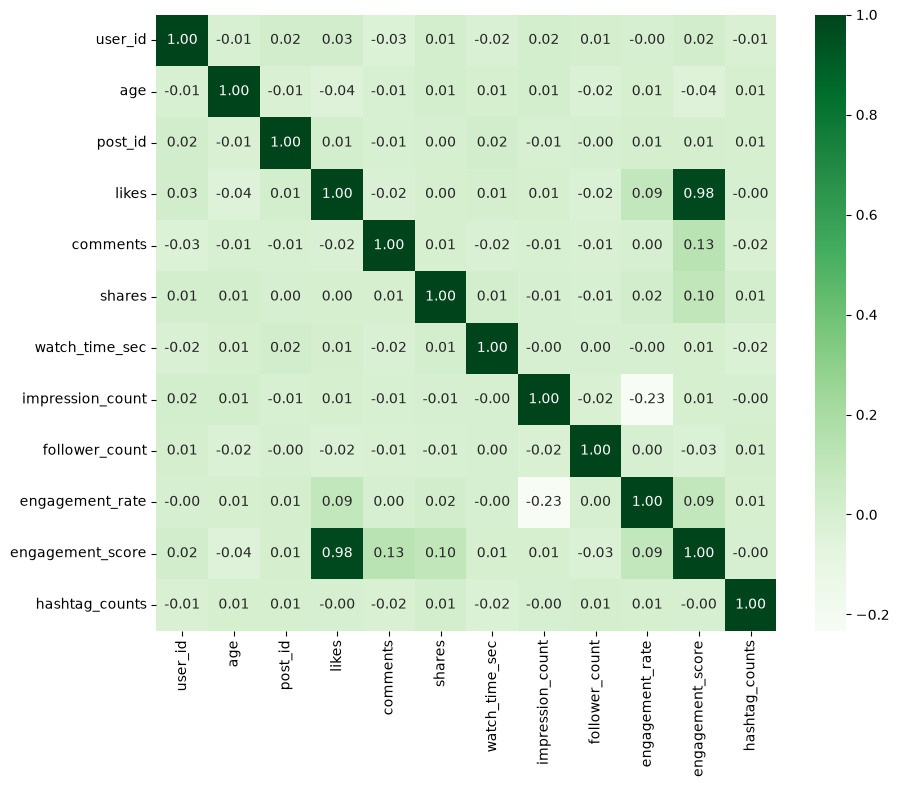

In [72]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="Greens",fmt=".2f")
plt.show()

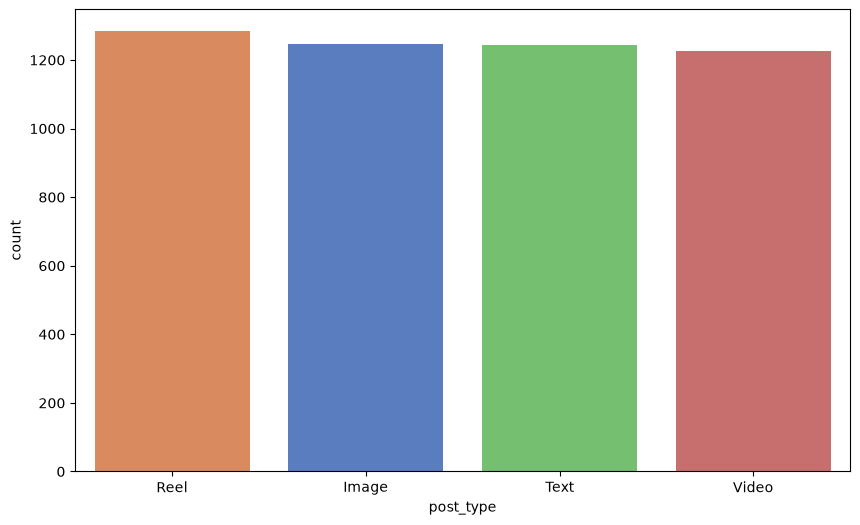

In [82]:
plt.figure(figsize=(10, 6),dpi=100)
sns.countplot(
    data=df,
    x='post_type',
    order=df['post_type'].value_counts().index,
    palette='muted',hue='post_type')
plt.show()

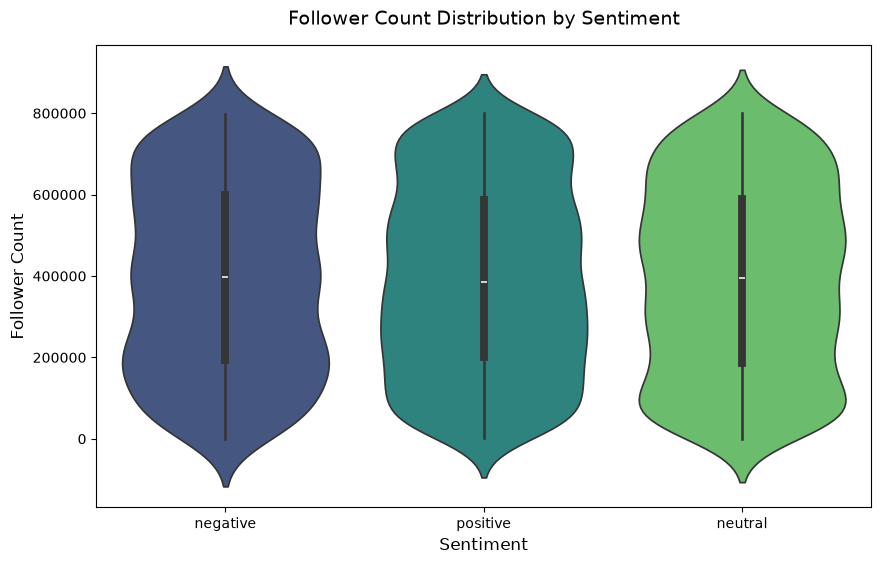

In [85]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x='sentiment',y='follower_count',hue="sentiment",palette='viridis')
plt.title('Follower Count Distribution by Sentiment',fontsize=14, pad=15)
plt.xlabel('Sentiment', fontsize=12)
plt.ylabel('Follower Count', fontsize=12)
plt.show()

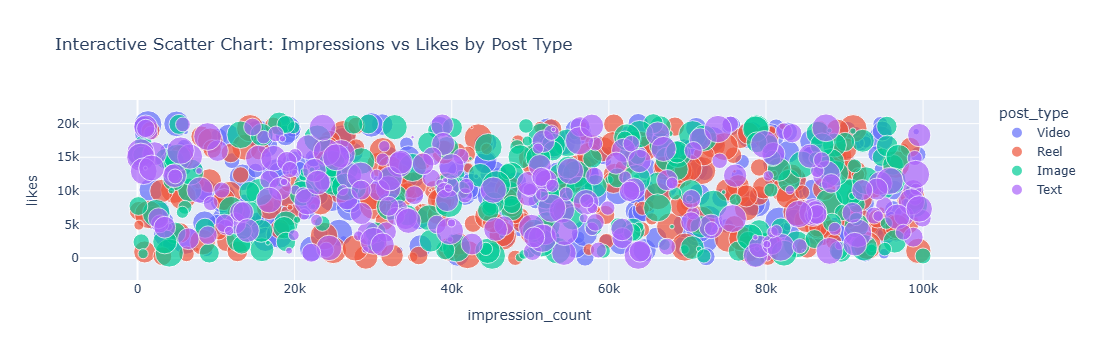

In [87]:
fig_plotly = px.scatter(
    df.sample(n=min(1000, len(df))), 
    x="impression_count", 
    y="likes", 
    color="post_type", 
    size="shares" if "shares" in df.columns else None, 
    hover_data=["post_category"] if "post_category" in df.columns else None, 
    title="Interactive Scatter Chart: Impressions vs Likes by Post Type"
)
fig_plotly.show()

### Final Insights should Include following analysis 

##### Content Performance 

Which post types have highest engagement? 

Best-performing content category? 

Which countries have highest avg engagement rate?  

##### User Trends 

How age affects engagement 

Performance difference for verified accounts[Text Wrapping Break] 

##### Behavioral Insights 

Best time of day for impressions[Text Wrapping Break] 

Device type impact on watch time[Text Wrapping Break] 

##### Sentiment Analysis 

Which sentiment performs best[Text Wrapping Break] 

Behavior of negative/neutral sentiment posts 

#### Content Performance

In [91]:
print('highest post :\n',df.groupby('post_type')['engagement_rate'].mean(),'\n\nbest performing content:\n',
df.groupby('post_category')['engagement_rate'].mean(),'\nHighest avg engagement rate:\n',
df.groupby('country')['engagement_rate'].mean())

highest post :
 post_type
Image    0.895646
Reel     0.783047
Text     1.064549
Video    1.122365
Name: engagement_rate, dtype: float64 

best performing content:
 post_category
Education    0.844222
Fashion      0.807109
Fitness      0.865628
Food         1.358628
Lifestyle    1.091019
Music        0.888803
Tech         1.160475
Travel       0.702223
Name: engagement_rate, dtype: float64 
Highest avg engagement rate:
 country
Australia    1.324339
Brazil       1.540704
Canada       0.916659
France       1.146402
Germany      0.759000
India        0.655005
Japan        0.769623
Uae          1.112352
Uk           0.850966
Usa          0.576580
Name: engagement_rate, dtype: float64



- Highest post type: Video has the highest average engagement rate (1.12), followed by Text (1.06).
- Best-performing category: Food leads with 1.36, followed by Lifestyle (1.09) and Tech (1.16).
- Country performance: Brazil has the highest average engagement rate (1.54), followed by Australia (1.32) and France (1.15).
- Lowest-performing post type: Reel has the lowest average engagement rate (0.78).
- Lowest-performing category: Travel has the lowest average engagement rate (0.70).
Conclusion: Video posts and food-related content attract higher engagement. Brazil shows the strongest average engagement among the listed countries, while travel content and reels may need improvements to increase engagement

#### User Trends

In [96]:
print('age by engagement rate:\n',df.groupby('age')['engagement_rate'].mean().sort_values(ascending=False).head(5),'\n\nverified account:\n',
      df.groupby('is_verified')['engagement_rate'].mean())

age by engagement rate:
 age
24    2.897327
55    2.599106
51    2.397295
48    1.675878
50    1.552627
Name: engagement_rate, dtype: float64 

verified account:
 is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64



User insight: Engagement peaks strongly among younger adults around age 24 (2.89%), as well as mature demographics in the 50–55 age bracket.

Account Verification: Verified accounts achieve slightly higher average engagement (1.05%) compared to unverified accounts (0.95%).

#### Behavioral Insights

In [99]:
df.groupby('posted_at')['impression_count'].mean().sort_values(ascending=False).head(5)

posted_at
2023-12-02    98263.5
2023-08-10    90304.5
2023-09-06    89909.0
2023-02-22    84897.0
2023-12-16    81594.0
Name: impression_count, dtype: float64


Top Performing Days: The highest average impression counts are concentrated heavily around late autumn and winter dates—specifically December 2, 2023 (averaging ~98,263 impressions) and August 10, 2023 (~90,304 impressions).

In [100]:
df.groupby('device_type')['watch_time_sec'].mean().sort_values(ascending=False)

device_type
Mobile     4087.830760
Tablet     3979.736429
Desktop    3974.792521
Name: watch_time_sec, dtype: float64

Mobile Leads Watch Time: Users on Mobile devices record the highest average watch time (4,087.83 seconds), followed by Tablets (~3,979 seconds) and Desktops (~3,974 seconds)Mobile devices drive the highest content consumption duration. This highlights that your audience predominantly consumes video and media content on-the-go via smartphones, making mobile-first content optimization crucial for maximizing watch retention.

#### Sentiment Analysis

In [98]:
df.groupby("sentiment")["engagement_rate"].mean()

sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64

insight: Content that provokes negative emotions, debates, strong reactions, or critical discussions tends to drive slightly higher engagement rates than positive or neutral posts, highlighting the tendency for provocative or critical content to capture more audience interaction.

High Conversational Depth: Neutral sentiment posts consistently yield the highest average engagement rates.